# 02 - Exploratory data analysis

Goal: understand the data before modelling. Nothing is modified here; the findings that drive preprocessing are summarised at the end.

- One row is one patient-hour. `SepsisLabel = 1` starts 6 hours **before** clinical sepsis onset.
- `patient_id` and `hospital` (A/B) were added in `01_load_data`.
- Patient-level questions collapse the rows to one line per patient first; modelling questions use rows.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

PROCESSED_DIR = Path("../data/processed")  # pickles live here (created by the notebooks)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df = pd.read_pickle(PROCESSED_DIR / "DataFrame.pkl")

## 1. Structure

In [3]:
df.shape

(1552210, 43)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1552210 entries, 0 to 1552209
Data columns (total 43 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   HR                1398811 non-null  float64
 1   O2Sat             1349474 non-null  float64
 2   Temp              525226 non-null   float64
 3   SBP               1325945 non-null  float64
 4   MAP               1358940 non-null  float64
 5   DBP               1065656 non-null  float64
 6   Resp              1313875 non-null  float64
 7   EtCO2             57636 non-null    float64
 8   BaseExcess        84145 non-null    float64
 9   HCO3              65028 non-null    float64
 10  FiO2              129365 non-null   float64
 11  pH                107573 non-null   float64
 12  PaCO2             86301 non-null    float64
 13  SaO2              53561 non-null    float64
 14  AST               25183 non-null    float64
 15  BUN               106568 non-null   float64
 16  Alkalinepho

In [5]:
df.describe()

,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel
count,1.398811e+06,1.349474e+06,525226.000000,1.325945e+06,1.358940e+06,1.065656e+06,1.313875e+06,57636.000000,84145.000000,65028.000000,...,99447.000000,10242.000000,92209.000000,1.552210e+06,1.552210e+06,940250.000000,940250.000000,1.552202e+06,1.552210e+06,1.552210e+06
mean,8.458144e+01,9.719395e+01,36.977228,1.237505e+02,8.240010e+01,6.383056e+01,1.872650e+01,32.957657,-0.689919,24.075481,...,11.446405,287.385706,196.013911,6.200947e+01,5.592690e-01,0.496571,0.503429,-5.612512e+01,2.699499e+01,1.798468e-02
std,1.732524e+01,2.936924e+00,0.770014,2.323156e+01,1.634175e+01,1.395601e+01,5.098194e+00,7.951662,4.294297,4.376504,...,7.731013,153.002908,103.635366,1.638622e+01,4.964749e-01,0.499989,0.499989,1.622569e+02,2.900542e+01,1.328956e-01
min,2.000000e+01,2.000000e+01,20.900000,2.000000e+01,2.000000e+01,2.000000e+01,1.000000e+00,10.000000,-32.000000,0.000000,...,0.100000,34.000000,1.000000,1.400000e+01,0.000000e+00,0.000000,0.000000,-5.366860e+03,1.000000e+00,0.000000e+00
25%,7.200000e+01,9.600000e+01,36.500000,1.070000e+02,7.100000e+01,5.400000e+01,1.500000e+01,28.000000,-3.000000,22.000000,...,7.600000,184.000000,126.000000,5.168000e+01,0.000000e+00,0.000000,0.000000,-4.705000e+01,1.100000e+01,0.000000e+00
50%,8.350000e+01,9.800000e+01,37.000000,1.210000e+02,8.000000e+01,6.200000e+01,1.800000e+01,33.000000,0.000000,24.000000,...,10.300000,250.000000,181.000000,6.400000e+01,1.000000e+00,0.000000,1.000000,-6.030000e+00,2.100000e+01,0.000000e+00
75%,9.550000e+01,9.950000e+01,37.500000,1.380000e+02,9.200000e+01,7.200000e+01,2.150000e+01,38.000000,1.000000,26.800000,...,13.800000,349.000000,244.000000,7.400000e+01,1.000000e+00,1.000000,1.000000,-4.000000e-02,3.400000e+01,0.000000e+00
max,2.800000e+02,1.000000e+02,50.000000,3.000000e+02,3.000000e+02,3.000000e+02,1.000000e+02,100.000000,100.000000,55.000000,...,440.000000,1760.000000,2322.000000,1.000000e+02,1.000000e+00,1.000000,1.000000,2.399000e+01,3.360000e+02,1.000000e+00


**Findings**
- 1,552,210 rows x 43 columns (38 float, 3 int, 2 string), about 509 MB in memory.
- Vitals are mostly present (`HR` 90%, `SBP` 85%, `Temp` only 34%). Most lab values are under 10% filled; `Bilirubin_direct` is 0.2%.
- `describe()` shows values sitting on round limits (min 20 for `HR`, `SBP`, `MAP`, `DBP`; max 300 for `SBP`, `MAP`, `DBP`; max 100 for `EtCO2`, `BaseExcess`), which looks like clipping in the source. Handled in preprocessing.

## 2. Missing data
Percentage of missing values per column and hospital.

In [6]:
df.isna().groupby(df["hospital"]).mean()*100

,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,patient_id,hospital
hospital,,,,,,,,,,,,,,,,,,,,,
A,7.743336,12.032042,66.224255,15.211177,10.232405,48.125763,9.776833,100.000000,89.574863,91.949406,...,93.482913,0.0,0.0,48.868346,48.868346,0.001012,0.0,0.0,0.0,0.0
B,12.101129,14.128308,66.098859,13.919251,14.752328,13.944580,21.138853,92.436171,99.768502,99.814828,...,94.657445,0.0,0.0,29.632084,29.632084,0.000000,0.0,0.0,0.0,0.0


### Ward columns (`Unit1`, `Unit2`)
Is the ward missing for whole patients or single hours, which combinations occur, and how does the sepsis rate vary by hospital and ward?

In [7]:
df[["Unit1", "Unit2"]].isna().groupby(df["patient_id"]).mean().T

patient_id,p000001,p000002,p000003,p000004,p000005,p000006,p000007,p000008,p000009,p000010,...,p119991,p119992,p119993,p119994,p119995,p119996,p119997,p119998,p119999,p120000
Unit1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
Unit2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0


In [8]:
df[["Unit1", "Unit2"]].value_counts(dropna=False).reset_index()

,Unit1,Unit2,count
0,NaN,NaN,611960
1,0.0,1.0,473349
2,1.0,0.0,466901


In [9]:
patients = df[["patient_id", "hospital", "Unit1", "Unit2", "SepsisLabel"]].groupby(df["patient_id"]).max()
conditions = [
    patients["Unit1"] == 1,
    patients["Unit2"] == 1,
    patients["Unit1"].isna() & patients["Unit2"].isna()
]
choices = ["MICU", "SICU", "NoUnit"]
patients["Unit"] = np.select(conditions, choices, default="Other")
patients = patients.drop(["Unit1", "Unit2"], axis=1)
patients.groupby(["hospital", "Unit"])["SepsisLabel"].agg(["mean", "count"])

mean  count
hospital Unit                   
A        MICU    0.107784   5344
         NoUnit  0.104180   9522
         SICU    0.040585   5470
B        MICU    0.056334   6923
         NoUnit  0.053158   6095
         SICU    0.061300   6982

### Largest differences between the hospitals

In [10]:
miss = df.isna().groupby(df["hospital"]).mean()
miss.loc["difference"] = (miss.loc["A"] - miss.loc["B"]).abs()
miss.T.sort_values("difference", ascending=False).T

,DBP,Unit2,Unit1,FiO2,Resp,BaseExcess,Glucose,pH,HCO3,Chloride,...,Fibrinogen,Temp,Bilirubin_direct,HospAdmTime,Age,Gender,ICULOS,SepsisLabel,patient_id,hospital
hospital,,,,,,,,,,,,,,,,,,,,,
A,0.481258,0.488683,0.488683,0.858070,0.097768,0.895749,0.877684,0.885329,0.919494,0.916761,...,0.992369,0.662243,0.998504,0.00001,0.0,0.0,0.0,0.0,0.0,0.0
B,0.139446,0.296321,0.296321,0.977415,0.211389,0.997685,0.778397,0.977745,0.998148,0.993846,...,0.994472,0.660989,0.997627,0.00000,0.0,0.0,0.0,0.0,0.0,0.0
difference,0.341812,0.192363,0.192363,0.119344,0.113620,0.101936,0.099286,0.092417,0.078654,0.077086,...,0.002103,0.001254,0.000877,0.00001,0.0,0.0,0.0,0.0,0.0,0.0


**Findings**
- Core vitals are recorded similarly in both hospitals. Largest gaps: `DBP` 48% missing in A vs 14% in B, `EtCO2` never recorded in A, `Unit1`/`Unit2` 49% vs 30% missing, and blood-gas values recorded far more often in A (`BaseExcess` filled in ~10% of rows in A vs ~0.2% in B).
- Ward information is all-or-nothing per patient and only three combinations occur, so `Unit1`/`Unit2` are merged into MICU / SICU / NoUnit.
- Sepsis rate by hospital and ward:

| Hospital | MICU | SICU | NoUnit |
|---|---|---|---|
| A | 10.8% (n=5,344) | 4.1% (n=5,470) | 10.4% (n=9,522) |
| B | 5.6% (n=6,923) | 6.1% (n=6,982) | 5.3% (n=6,095) |

The hospitals differ in how data is recorded, so a model could learn "which hospital" instead of sepsis. This motivates the train-on-A / test-on-B check at the end.

## 3. Class imbalance
Share of septic patients and share of positive hours, overall and per hospital.

In [11]:
separate_data = df.groupby(df["patient_id"]).max().groupby("hospital")["SepsisLabel"].mean().reset_index()
all_data = df.groupby(df["patient_id"]).max()["SepsisLabel"].mean()
pd.concat([pd.DataFrame({'hospital':['all'], 'SepsisLabel':[all_data]}), separate_data]).reset_index(drop = True)

,hospital,SepsisLabel
0,all,0.072689
1,A,0.088021
2,B,0.057100


In [12]:
df["SepsisLabel"].mean()

np.float64(0.01798467990800214)

**Findings**
- 7.3% of patients develop sepsis (2,932 of 40,336): 8.8% in A, 5.7% in B.
- Only 1.8% of patient-hours are labelled 1. Accuracy is meaningless; precision-recall metrics, class weights and patient-level splits are required.

## 4. Length of stay
Maximum `ICULOS` per patient (hours).

In [13]:
ICULOS_patient = df[["patient_id", "ICULOS", "SepsisLabel"]].groupby("patient_id").max()
display(ICULOS_patient)
display(ICULOS_patient["ICULOS"].describe().reset_index())

,ICULOS,SepsisLabel
patient_id,,
p000001,54,0
p000002,23,0
p000003,48,0
p000004,29,0
p000005,49,0
...,...,...
p119996,48,0
p119997,25,0
p119998,49,0


,index,ICULOS
0,count,40336.000000
1,mean,39.010115
2,std,22.924641
3,min,8.000000
4,25%,24.000000
5,50%,39.000000
6,75%,47.000000
7,max,336.000000


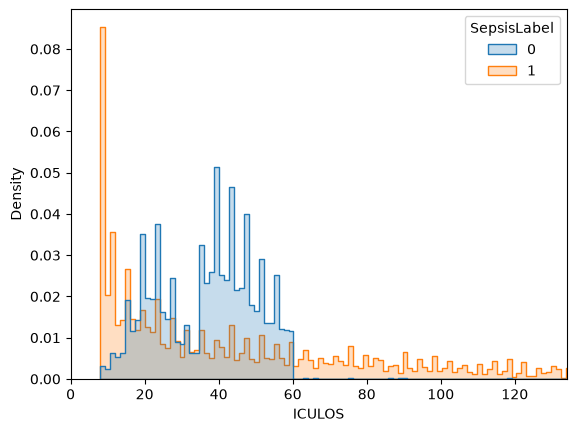

In [14]:
sns.histplot(
    data=ICULOS_patient,
    x="ICULOS",
    hue="SepsisLabel",
    stat="density",
    common_norm=False,
    element="step",
)
plt.xlim(0, ICULOS_patient["ICULOS"].quantile(0.99))
plt.show()

In [15]:
display(ICULOS_patient.groupby("SepsisLabel")["ICULOS"].describe())

,count,mean,std,min,25%,50%,75%,max
SepsisLabel,,,,,,,,
0,37404.0,37.410437,15.956682,8.0,25.0,39.0,47.0,336.0
1,2932.0,59.417462,59.445450,8.0,16.0,38.0,82.0,336.0


**Findings**
- Mean stay 39 h (min 8, max 336). Medians are almost equal for non-septic (39 h) and septic (38 h) patients, but septic stays have a spike at 8 h and a long tail (mean 59 h vs 37 h).
- Non-septic stays almost all end by ~60 h, which looks like an artefact of how the challenge data was assembled. `ICULOS` is therefore a risky feature and is not used as a model input.

## 5. Patient characteristics
Age and gender are constant per patient, so they are summarised per patient.

In [16]:
display(df[["patient_id", "Age"]].groupby("patient_id").mean().describe())
display(df[["patient_id", "Gender"]].groupby("patient_id").mean().apply(pd.Series.value_counts, normalize=True))

,Age
count,40336.000000
mean,61.643423
std,16.482946
min,14.000000
25%,51.000000
50%,63.110000
75%,74.000000
max,100.000000


,Gender
Gender,
1.0,0.559451
0.0,0.440549


SepsisLabel                 
               sum  count      mean
Gender                             
0             1193  17770  0.067136
1             1739  22566  0.077063

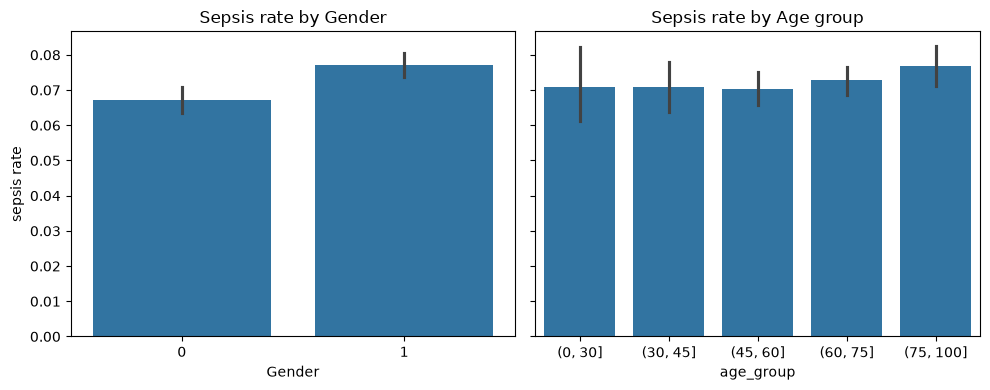

In [17]:
display(df[["patient_id", "Gender", "SepsisLabel"]].groupby("patient_id").max().groupby("Gender").agg(["sum", "count", "mean"]))
patient_demo = df[["patient_id", "Age", "Gender", "SepsisLabel"]].groupby("patient_id").max()
patient_demo["age_group"] = pd.cut(patient_demo["Age"], bins=[0, 30, 45, 60, 75, 100])
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(10, 4))
sns.barplot(data=patient_demo, x="Gender", y="SepsisLabel", ax=axes[0])
sns.barplot(data=patient_demo, x="age_group", y="SepsisLabel", ax=axes[1])
axes[0].set_title("Sepsis rate by Gender")
axes[1].set_title("Sepsis rate by Age group")
axes[0].set_ylabel("sepsis rate")
plt.tight_layout()
plt.show()

**Findings**
- Age: mean 62, range 14-100 (100 looks like a cap); 56% male.
- Sepsis rate: 6.7% for women, 7.7% for men, nearly flat across age groups (about 7-8%). Demographics carry little signal.

## 6. When does sepsis start?
First hour labelled 1 per septic patient.

In [18]:
df[df["SepsisLabel"] == 1].groupby("patient_id")["ICULOS"].min().describe().reset_index()

,index,ICULOS
0,count,2932.000000
1,mean,50.896317
2,std,59.363675
3,min,1.000000
4,25%,7.000000
5,50%,29.000000
6,75%,73.000000
7,max,331.000000


**Findings**
- Median first positive label at hour 29 (mean 51); a quarter of septic patients are flagged by hour 7. Many cases leave very little history, so features must work with short histories.

## 7. Vital signs and labs: sepsis vs non-sepsis
Per-patient means over the whole stay (caveat: this includes hours after onset).

In [19]:
mean_patient = df.drop(columns=["hospital"]).groupby("patient_id").mean()
display(mean_patient[mean_patient["SepsisLabel"] == 0].describe())
display(mean_patient[mean_patient["SepsisLabel"] != 0].describe())

,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel
count,37399.000000,37388.000000,37155.000000,37233.000000,37300.000000,30487.000000,37347.000000,2689.000000,11648.000000,18477.000000,...,35021.000000,3930.000000,35069.000000,37404.000000,37404.000000,23103.000000,23103.000000,37403.000000,37404.000000,37404.0
mean,83.390114,97.145814,36.830164,123.479056,82.722173,64.231033,18.451585,33.261021,-0.479558,24.434180,...,10.939038,299.093417,207.045402,61.611084,0.556812,0.489157,0.510843,-49.738715,19.465886,0.0
std,14.425896,2.092291,0.526411,17.790792,12.614941,10.939307,3.286736,10.340150,3.817667,3.835353,...,6.350920,151.370764,98.628509,16.491078,0.496769,0.499893,0.499893,133.191109,8.232277,0.0
min,30.258065,27.000000,30.500000,35.000000,22.000000,24.000000,1.000000,10.000000,-25.000000,5.000000,...,0.100000,35.000000,4.000000,14.000000,0.000000,0.000000,0.000000,-5366.860000,4.500000,0.0
25%,73.178908,96.148148,36.494200,110.543478,73.684211,56.533712,16.361111,28.500000,-2.166667,22.333333,...,7.550000,196.093750,143.000000,51.000000,0.000000,0.000000,0.000000,-42.365000,13.000000,0.0
50%,82.750000,97.377778,36.800000,121.412500,80.937500,63.020000,18.078947,33.250000,-0.375000,24.333333,...,10.100000,258.578431,191.666667,63.040000,1.000000,0.000000,1.000000,-6.200000,20.000000,0.0
75%,92.590326,98.473684,37.161111,134.789474,90.181818,70.788322,20.153846,37.500000,1.000000,26.500000,...,13.150000,360.000000,251.666667,74.000000,1.000000,1.000000,1.000000,-0.050000,24.500000,0.0
max,156.142857,100.000000,39.737500,214.818182,149.000000,135.722222,56.250000,100.000000,25.000000,54.333333,...,328.366667,1246.000000,2322.000000,100.000000,1.000000,1.000000,1.000000,23.990000,320.000000,0.0


,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel
count,2932.000000,2930.000000,2897.000000,2821.000000,2932.000000,2438.000000,2918.000000,527.000000,1562.000000,1740.000000,...,2690.000000,585.000000,2690.000000,2932.000000,2932.000000,1616.000000,1616.000000,2932.000000,2932.000000,2932.000000
mean,89.098635,97.256016,37.005770,121.241073,80.539163,62.405747,19.643555,32.223234,-0.409088,23.858023,...,12.785131,339.719604,203.248386,62.055982,0.593111,0.597772,0.402228,-78.768776,30.516030,0.396037
std,16.135403,2.133561,0.756520,18.218619,11.943751,10.727475,4.525895,9.370139,4.090158,4.373693,...,8.937061,189.624180,112.295179,16.376043,0.491338,0.490499,0.490499,204.114142,30.073144,0.332492
min,45.650000,67.937500,32.442857,69.113636,46.875000,27.333333,1.000000,10.000000,-15.166667,7.000000,...,0.100000,55.500000,4.000000,17.000000,0.000000,0.000000,0.000000,-3141.550000,4.500000,0.005988
25%,77.468207,96.100670,36.570926,107.928571,72.222895,55.119318,16.809943,27.679988,-2.839583,21.328125,...,8.500862,205.333333,126.500000,51.550000,0.000000,0.000000,0.000000,-67.727500,8.500000,0.117647
50%,88.425926,97.574014,37.003158,119.663043,79.252660,61.548291,19.250000,32.411765,-0.102632,24.000000,...,11.500000,294.000000,186.071429,64.000000,1.000000,1.000000,0.000000,-2.935000,19.500000,0.263158
75%,99.305882,98.811252,37.501935,132.737179,87.750000,68.877171,22.160511,36.348558,1.962674,26.458333,...,15.154687,423.500000,256.000000,74.660000,1.000000,1.000000,1.000000,-0.020000,42.000000,0.629464
max,174.697674,100.000000,39.610000,192.750000,140.724138,113.285714,40.214286,100.000000,17.600000,43.000000,...,168.600000,1383.000000,1021.000000,100.000000,1.000000,1.000000,1.000000,16.020000,286.000000,1.000000


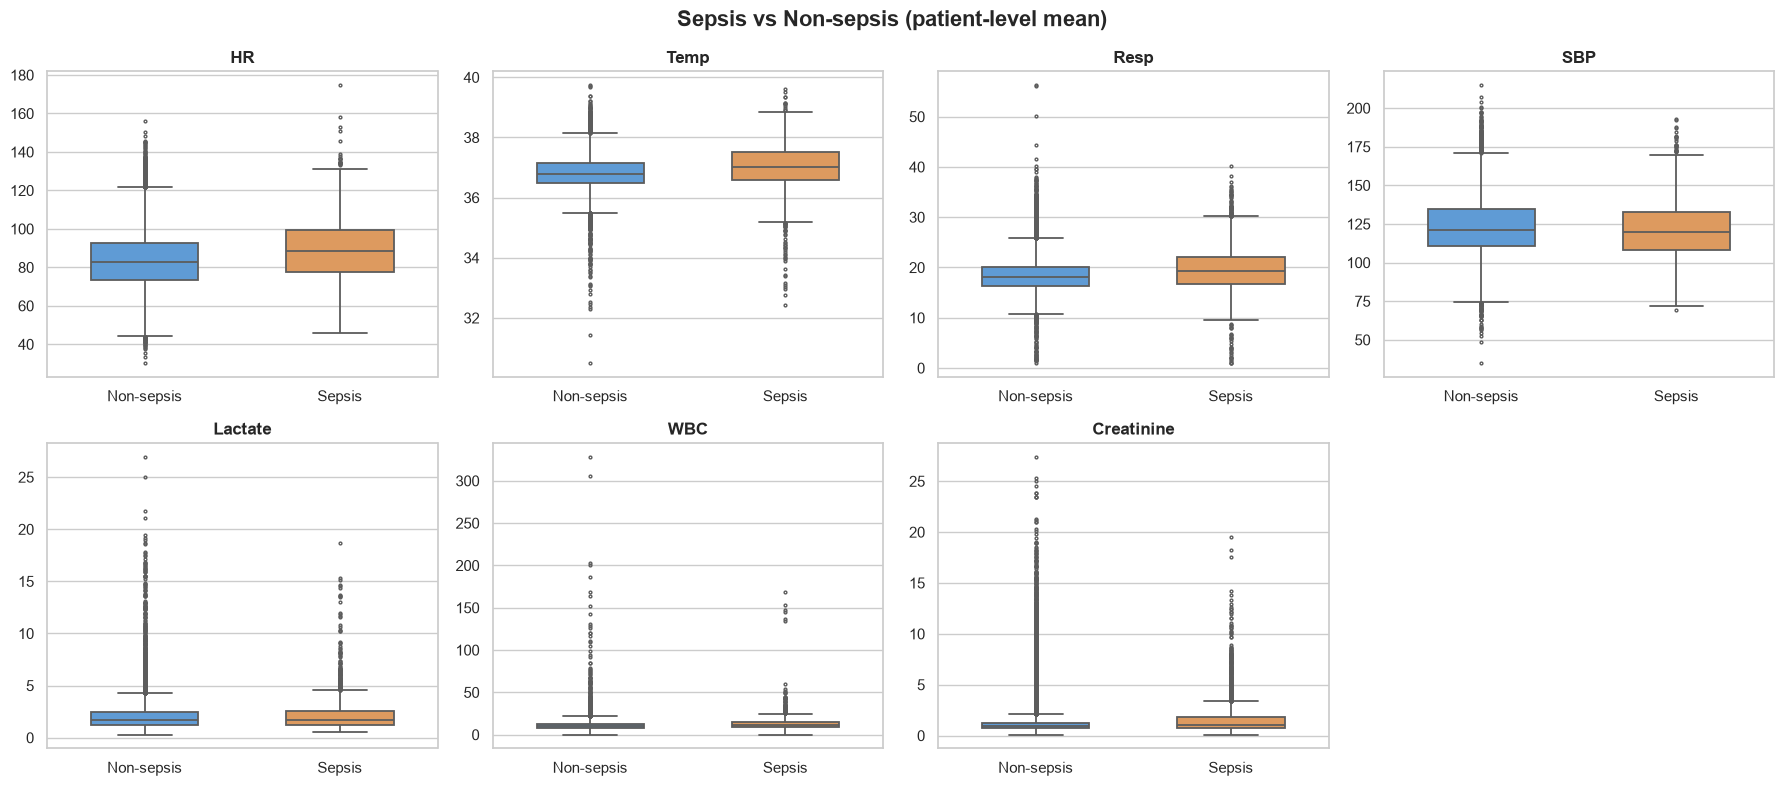

In [20]:
features = ["HR", "Temp", "Resp", "SBP", "Lactate", "WBC", "Creatinine"]
plot_df = mean_patient.assign(
    group=(mean_patient["SepsisLabel"] > 0).map({False: "Non-sepsis", True: "Sepsis"})
)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flat, features):
    sns.boxplot(
        data=plot_df, x="group", y=col, hue="group",
        palette={"Non-sepsis": "#4C9BE8", "Sepsis": "#F2994A"},
        width=0.55, linewidth=1.3, fliersize=2, legend=False, ax=ax,
    )
    ax.set_title(col, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")

axes.flat[-1].set_visible(False)
fig.suptitle("Sepsis vs Non-sepsis (patient-level mean)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

**Findings**
- Directions match clinical expectation (septic patients: higher `HR` 89 vs 83, `Temp`, `Resp`, `WBC`; slightly lower `SBP`/`MAP`), but the distributions overlap heavily. No single variable separates the groups.

## 8. Hospital A vs B
Per-patient means by hospital.

In [21]:
df[["patient_id", "hospital", "HR", "Temp", "Age", "Lactate"]].groupby(["patient_id", "hospital"]).mean().groupby("hospital").mean()

,HR,Temp,Age,Lactate
hospital,,,,
A,84.548909,36.913893,62.621613,2.093052
B,83.048710,36.771305,60.648800,2.274263


**Findings**
- Patients look alike (`HR` 84.5 vs 83.0, `Temp` 36.91 vs 36.77, age 62.6 vs 60.6). The hospitals differ more in sepsis prevalence and in what is recorded than in patient physiology.

## 9. Is taking a measurement informative?
Measurements per ICU hour, by sepsis status.

In [22]:
Test_data = df[["patient_id", "SepsisLabel", "Lactate", "WBC", "Creatinine", "ICULOS"]].groupby("patient_id").agg({
    "SepsisLabel":"max", 
    "Lactate":"count", 
    "WBC":"count", 
    "Creatinine":"count",
    "ICULOS":"max"
})
Test_data["Lactate"] = Test_data["Lactate"]/Test_data["ICULOS"]
Test_data["WBC"] = Test_data["WBC"]/Test_data["ICULOS"]
Test_data["Creatinine"] = Test_data["Creatinine"]/Test_data["ICULOS"]
Test_data.groupby("SepsisLabel").mean()

,Lactate,WBC,Creatinine,ICULOS
SepsisLabel,,,,
0,0.021575,0.062129,0.059452,37.410437
1,0.066058,0.082826,0.076182,59.417462


**Findings**
- Septic patients are measured more often: `Lactate` about 3.1x (0.066 vs 0.022 per hour), `WBC` and `Creatinine` about 1.3x. "Was it measured?" is a signal, so measurement indicators are kept as features. Whole-stay frequencies would leak the outcome, so the model only uses counts up to the current hour.

## 10. Summary and decisions for preprocessing
1. Split **by patient**, stratified by sepsis status.
2. Fit imputation statistics on the training split only.
3. Build features only from the past (rolling means, differences, time since last measurement, measurement counts).
4. Handle clipped and implausible values explicitly.
5. Use precision-recall metrics; handle imbalance with class weights.
6. Do not use `ICULOS`, `patient_id` or `hospital` as model inputs; evaluate train-on-A / test-on-B.

Not covered: correlation analysis.